# 02 · DML on synthetic data

On synthetic data the true elasticity is known (**−1.8**), so every method can be scored.
This notebook compares:

* four naive OLS baselines (`econocausal.baselines`)
* my own DML implementation (`econocausal.dml`)
* EconML's `LinearDML` with the same inputs (`econocausal.models`)

Data design: [`docs/synthetic_data.md`](../docs/synthetic_data.md).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from econocausal.baselines import run_baselines
from econocausal.data.db import get_engine, save_results
from econocausal.dml import estimate_elasticity
from econocausal.models import estimate_elasticity_econml
from econocausal.paths import PROJECT_ROOT
from econocausal.simulate import simulate_panel
from econocausal.viz import BLUE, GREY, TEXT_MUTED, save_figure, set_style

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

df = simulate_panel()
TRUE = df.attrs["true_elasticity"]
print(f"{len(df):,} rows, {df['stock_code'].nunique()} products, true elasticity {TRUE:.1f}")

31,200 rows, 300 products, true elasticity -1.8


## 1. Fit every method

In [2]:
baselines = run_baselines(df, "synthetic", true_value=TRUE)

dml_rows = []
for method, fit in [("dml_manual", estimate_elasticity), ("dml_econml", estimate_elasticity_econml)]:
    r = fit(df).to_dict()
    dml_rows.append({"dataset": "synthetic", "method": method, **r, "true_value": TRUE,
                     "error": r["estimate"] - TRUE})

comparison = pd.concat([baselines, pd.DataFrame(dml_rows)], ignore_index=True)
comparison["ci_covers_truth"] = (comparison["ci_low"] < TRUE) & (TRUE < comparison["ci_high"])
comparison[["method", "estimate", "std_error", "ci_low", "ci_high", "error", "ci_covers_truth",
            "outcome_r2", "treatment_r2"]]

,method,estimate,std_error,ci_low,ci_high,error,ci_covers_truth,outcome_r2,treatment_r2
0,pooled,-1.147,0.055,-1.256,-1.039,0.653,False,NaN,NaN
1,product_fe,-2.736,0.012,-2.760,-2.713,-0.936,False,NaN,NaN
2,product_week_fe,-2.908,0.012,-2.931,-2.885,-1.108,False,NaN,NaN
3,product_week_fe_controls,-1.927,0.019,-1.965,-1.889,-0.127,False,NaN,NaN
4,dml_manual,-1.806,0.023,-1.851,-1.760,-0.006,True,0.727,0.849
5,dml_econml,-1.816,0.023,-1.861,-1.771,-0.016,True,0.727,0.850


Only the two DML estimators have confidence intervals that contain the true value. The
baselines are not just noisy, they are **biased**: their intervals are narrow and in the wrong place.

The nuisance R² values show how much of quantity and price the confounders explain out of sample.
About 85% of the within-product price variation is explained by season and customer mix; the
elasticity is estimated from the remaining ~15%.

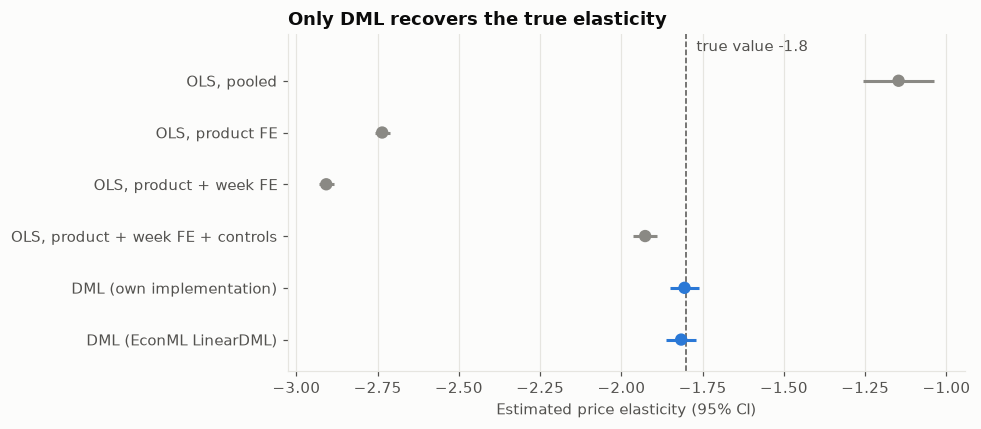

In [3]:
labels = {
    "pooled": "OLS, pooled",
    "product_fe": "OLS, product FE",
    "product_week_fe": "OLS, product + week FE",
    "product_week_fe_controls": "OLS, product + week FE + controls",
    "dml_manual": "DML (own implementation)",
    "dml_econml": "DML (EconML LinearDML)",
}
plot = comparison.iloc[::-1].reset_index(drop=True)
colors = [BLUE if m.startswith("dml") else GREY for m in plot["method"]]

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(plot))
ax.errorbar(plot["estimate"], y,
            xerr=[plot["estimate"] - plot["ci_low"], plot["ci_high"] - plot["estimate"]],
            fmt="none", ecolor=colors, elinewidth=2, capsize=0)
ax.scatter(plot["estimate"], y, color=colors, s=50, zorder=3)
ax.axvline(TRUE, color=TEXT_MUTED, linestyle="--", linewidth=1)
ax.set_ylim(-0.6, len(plot) - 0.1)
ax.text(TRUE, len(plot) - 0.35, f"  true value {TRUE:.1f}", color=TEXT_MUTED, va="center")
ax.set_yticks(y, [labels[m] for m in plot["method"]])
ax.set_xlabel("Estimated price elasticity (95% CI)")
ax.set_title("Only DML recovers the true elasticity")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, "08_method_comparison_synthetic")

## 2. Other scenarios

* **Heterogeneous:** elasticity differs by category, average still −1.8. DML targets the average.
* **Hidden confounder:** a demand shock that also moves price is left out of the data. No method
  can correct for it; this is the main assumption DML relies on.

In [4]:
scenarios = []
for name, kwargs in [("default", {}), ("heterogeneous", {"heterogeneous": True}),
                     ("hidden confounder", {"hidden_confounding": 1.0})]:
    data = simulate_panel(**kwargs)
    best_ols = run_baselines(data, "synthetic", TRUE).set_index("method").loc["product_week_fe_controls"]
    dml = estimate_elasticity(data)
    scenarios.append({
        "scenario": name,
        "best OLS": best_ols["estimate"],
        "DML": dml.estimate,
        "DML CI": f"{dml.ci_low:.2f} to {dml.ci_high:.2f}",
        "DML CI covers -1.8": dml.ci_low < TRUE < dml.ci_high,
    })
pd.DataFrame(scenarios).set_index("scenario")

,best OLS,DML,DML CI,DML CI covers -1.8
scenario,,,,
default,-1.927,-1.806,-1.85 to -1.76,True
heterogeneous,-1.922,-1.806,-1.87 to -1.74,True
hidden confounder,-0.358,0.220,0.19 to 0.25,False


## 3. Save results

In [5]:
out = PROJECT_ROOT / "reports" / "method_comparison_synthetic.csv"
comparison.round(4).to_csv(out, index=False)
save_results(comparison.drop(columns="ci_covers_truth"), get_engine())
print(f"Saved {len(comparison)} rows to {out.relative_to(PROJECT_ROOT)} and the results table")

Saved 6 rows to reports\method_comparison_synthetic.csv and the results table
